# Learning from preferences: reward models, RLHF, DPO, RLOO and GRPO, with the true reward known

**Code:** [`envs/preference_toy.py`](../envs/preference_toy.py) · [`sequence_policy.py`](../algos/sequence_policy.py) · [`reward_model.py`](../algos/reward_model.py) · [`rlhf.py`](../algos/rlhf.py) · [`dpo.py`](../algos/dpo.py) · [`experiments/preference_sweep.py`](../experiments/preference_sweep.py)
**Papers:** Christiano 2017 ([PDF](../papers/preference-llm/christiano-2017-human-preferences.pdf)), Stiennon 2020 ([PDF](../papers/preference-llm/stiennon-2020-summarize-hf.pdf)), Ouyang 2022 ([PDF](../papers/preference-llm/ouyang-2022-instructgpt.pdf)), Bai 2022 ([PDF](../papers/preference-llm/bai-2022-constitutional-ai.pdf)), Gao 2022 ([PDF](../papers/preference-llm/gao-2022-scaling-laws-overoptimization.pdf)), Rafailov 2023 ([PDF](../papers/preference-llm/rafailov-2023-dpo.pdf)), Singhal 2023 ([PDF](../papers/preference-llm/singhal-2023-length-bias.pdf)), Ahmadian 2024 ([PDF](../papers/preference-llm/ahmadian-2024-rloo.pdf)), Shao 2024 ([PDF](../papers/preference-llm/shao-2024-deepseekmath-grpo.pdf)) ·
**Notes:** [`papers/preference-llm/notes.md`](../papers/preference-llm/notes.md)

**This is a toy, on purpose.** A real RLHF run cannot measure its main failure: the true reward is a person's judgement, so when the policy over-optimises the reward model, nobody can say by how much.
Here a tiny GRU language model writes token sequences, and the true reward is a formula. Every method sees only preferences, exactly as in real RLHF; the formula is used only to score the results.
No real language model is trained in this notebook.

What you will see:

1. Preference data, a reward model fitted to it, and how its accuracy saturates.
2. RLHF with three advantage estimators — REINFORCE, RLOO, GRPO — on the same reward model.
3. **Over-optimisation, measured:** the proxy reward keeps rising while the true reward peaks and falls.
4. **Labelers who want something else:** a length-biased labeler, and a rule-following AI labeler.
5. **DPO:** the same preference data, no reward model, no sampling.

Runs live in about a minute; the sweeps are read from `experiments/results/preference/` (`python experiments/preference_sweep.py all`).

In [1]:
import json, pathlib, time
import numpy as np
import matplotlib.pyplot as plt
import torch

from algos import rlhf, sequence_policy as sp
from envs import preference_toy as toy

torch.set_num_threads(1)
plt.rcParams["figure.dpi"] = 110
ROOT = pathlib.Path("..") if pathlib.Path("../algos").exists() else pathlib.Path(".")
RESULTS = ROOT / "experiments/results/preference"

def load(prefix):
    return [json.loads(p.read_text()) for p in sorted(RESULTS.glob(f"{prefix}*.json"))]

## 0. The problem and the data

A **prompt** is an integer 0–7 meaning "write token p". A **response** is up to 12 tokens from a vocabulary of 8, ended by EOS.

$$r^*(p, y) = \#\{t \in y : t = p\} \;-\; 0.3 \times \#\{t \in y : t \ne p\}$$

So the best response repeats the requested token 12 times (true reward 12), and every other token costs 0.3.
The **reference policy** (what the "pretrained" model writes) uses the requested token 30% of the time and stops after 2–10 tokens: true reward about 1.2.

A **preference pair** is two reference responses to one prompt, labelled by which is better.
Labels are noisy, Bradley-Terry style: $P(y_1 \succ y_2) = \sigma\big((r^*(y_1) - r^*(y_2))/0.5\big)$.

| column | meaning |
| --- | --- |
| `prompt` | the requested token |
| `chosen`, `rejected` | the two responses, in label order |
| `r*(chosen)`, `r*(rejected)` | true rewards; not available to any method |

In [2]:
rng = np.random.default_rng(0)
pairs = toy.preference_data(rng, 8)
fmt = lambda y: " ".join(str(t) for t in y if t != toy.EOS)
print(f"{'prompt':>6}  {'chosen':<26} {'rejected':<26} {'r*(chosen)':>10} {'r*(rejected)':>12}")
for p, c, r in pairs:
    print(f"{p:>6}  {fmt(c):<26} {fmt(r):<26} {toy.true_reward(p, c):>10.1f} {toy.true_reward(p, r):>12.1f}")
flipped = sum(toy.true_reward(p, c) < toy.true_reward(p, r) for p, c, r in toy.preference_data(np.random.default_rng(1), 2_000))
print(f"\nlabel noise: in 2,000 pairs, the 'chosen' one has the LOWER true reward in {flipped} ({flipped / 20:.1f}%)")

prompt  chosen                     rejected                   r*(chosen) r*(rejected)
     6  6 6 6 6                    6 6 6 5 7 5 4                     4.0          1.8
     1  1 4                        1 0 2 4 6                         0.7         -0.2
     7  2 1 7 3 7                  5 7 1 3 2 0 7 2 2 6               1.1         -0.4
     6  3 6 6 7 6 1 6 7 1          0 6                               2.5          0.7
     5  6 7                        7 7 4 0 3 3                      -0.6         -1.8
     4  4 7 7 4 0 7 4 2 7 2        3 7                               0.9         -0.6
     1  1 1 1 4 1 1 4 1 4 0        1 7 1                             4.8          1.7
     6  6 6 2 6 6 6 6 4 3 2        6 5 2 0 6 6                       4.8          2.1

label noise: in 2,000 pairs, the 'chosen' one has the LOWER true reward in 213 (10.7%)


## 1. The pipeline in one picture

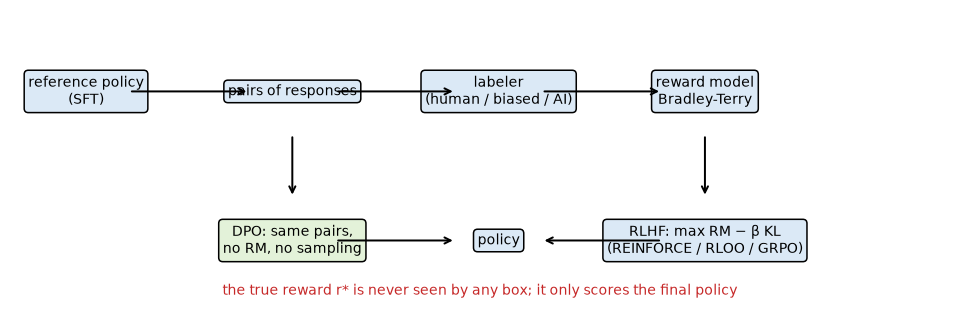

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.2)); ax.axis("off")
boxes = {"reference policy\n(SFT)": (0.08, 0.7), "pairs of responses": (0.3, 0.7), "labeler\n(human / biased / AI)": (0.52, 0.7),
         "reward model\nBradley-Terry": (0.74, 0.7), "RLHF: max RM − β KL\n(REINFORCE / RLOO / GRPO)": (0.74, 0.15),
         "DPO: same pairs,\nno RM, no sampling": (0.3, 0.15), "policy": (0.52, 0.15)}
for t, (x, y) in boxes.items():
    ax.text(x, y, t, ha="center", va="center", fontsize=9, bbox=dict(boxstyle="round", fc="#dbe9f6" if "DPO" not in t else "#e3f2d9"))
def arrow(a, b):
    ax.annotate("", xy=boxes[b], xytext=boxes[a], arrowprops=dict(arrowstyle="->", lw=1.3, shrinkA=30, shrinkB=30))
arrow("reference policy\n(SFT)", "pairs of responses"); arrow("pairs of responses", "labeler\n(human / biased / AI)")
arrow("labeler\n(human / biased / AI)", "reward model\nBradley-Terry"); arrow("reward model\nBradley-Terry", "RLHF: max RM − β KL\n(REINFORCE / RLOO / GRPO)")
arrow("RLHF: max RM − β KL\n(REINFORCE / RLOO / GRPO)", "policy"); arrow("pairs of responses", "DPO: same pairs,\nno RM, no sampling")
arrow("DPO: same pairs,\nno RM, no sampling", "policy")
ax.text(0.5, -0.05, "the true reward r* is never seen by any box; it only scores the final policy", ha="center", fontsize=9, color="#c62828")
plt.show()

## 2. The reward model

$P(y_w \succ y_l) = \sigma(r_\theta(x, y_w) - r_\theta(x, y_l))$, fitted by maximum likelihood ([`reward_model.py`](../algos/reward_model.py)).
Accuracy is the fraction of fresh reference pairs it orders the same way as the **true** reward.

    100 pairs: accuracy 0.690
    300 pairs: accuracy 0.753
  1,000 pairs: accuracy 0.870
  3,000 pairs: accuracy 0.893
 10,000 pairs: accuracy 0.899


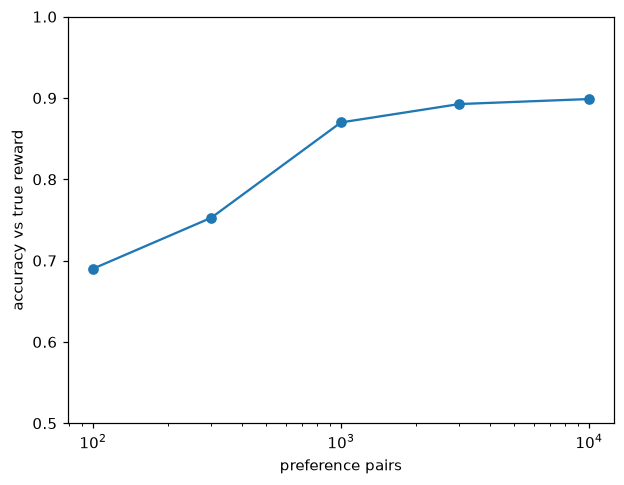

In [4]:
rm_rows = sorted(load("rm_accuracy__"), key=lambda r: r["n_pairs"])
for r in rm_rows: print(f"{r['n_pairs']:>7,} pairs: accuracy {r['accuracy']:.3f}")
plt.plot([r["n_pairs"] for r in rm_rows], [r["accuracy"] for r in rm_rows], "o-")
plt.xscale("log"); plt.xlabel("preference pairs"); plt.ylabel("accuracy vs true reward"); plt.ylim(0.5, 1); plt.show()

Accuracy saturates near 0.90. Section 0 measured why: 10.7% of the labels prefer the response with the lower true reward, so a model that fits the labellers perfectly is still wrong on about one pair in ten. More data cannot fix label noise.

## 3. RLHF with three advantage estimators

Objective $\max_\pi \mathbb{E}[r_{RM}(x,y)] - \beta\,\mathrm{KL}(\pi\,\|\,\pi_{ref})$, β = 0.05, 4 samples per prompt, 300 steps, 3 seeds, reward model from 3,000 pairs ([`rlhf.py`](../algos/rlhf.py)):

| estimator | advantage of sample i | paper |
| --- | --- | --- |
| mean | $R_i - \bar R_{\text{batch}}$ | REINFORCE with a baseline |
| RLOO | $R_i - \frac{1}{k-1}\sum_{j \ne i} R_j$ within the prompt's group | Ahmadian et al. 2024 |
| GRPO | $(R_i - \bar R_{\text{group}}) / \sigma_{\text{group}}$; KL as a separate loss term | Shao et al. 2024 |

 mean: final true reward [8.07, 8.11, 8.69], KL [11.3, 12.2, 11.7]
 rloo: final true reward [8.2, 8.8, 8.67], KL [11.8, 13.1, 13.5]
 grpo: final true reward [8.51, 8.48, 8.59], KL [16.4, 17.7, 17.4]


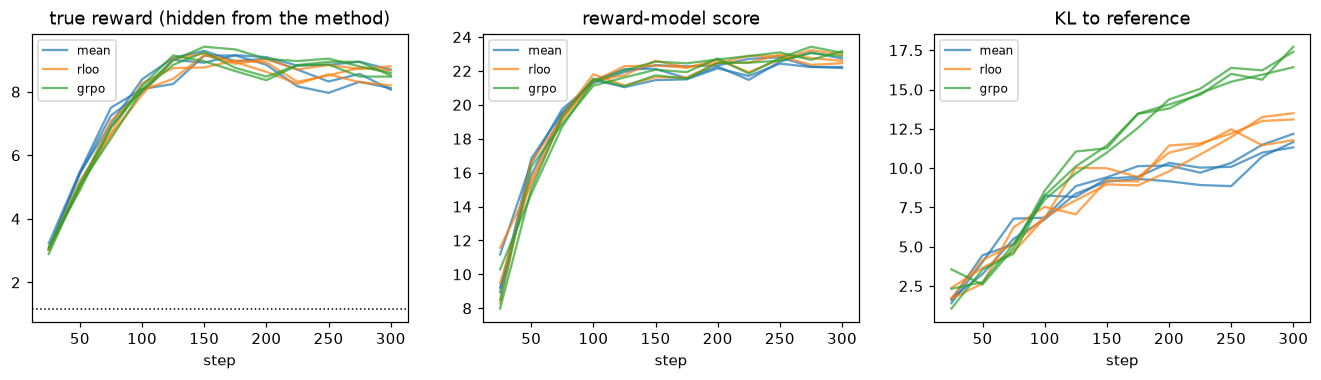

In [5]:
est = load("estimators__")
fig, axs = plt.subplots(1, 3, figsize=(15, 3.4))
for name, colour in (("mean", "tab:blue"), ("rloo", "tab:orange"), ("grpo", "tab:green")):
    runs = [r for r in est if r["estimator"] == name]
    for r in runs:
        steps = [e["step"] for e in r["log"]]
        for ax, key in zip(axs, ("true_reward", "proxy", "kl")):
            ax.plot(steps, [e[key] for e in r["log"]], color=colour, alpha=0.7, label=name if r is runs[0] else None)
    print(f"{name:>5}: final true reward {[round(r['log'][-1]['true_reward'], 2) for r in runs]}, KL {[round(r['log'][-1]['kl'], 1) for r in runs]}")
for ax, t in zip(axs, ("true reward (hidden from the method)", "reward-model score", "KL to reference")):
    ax.set_title(t); ax.set_xlabel("step"); ax.legend(fontsize=8)
axs[0].axhline(est[0]["sft"]["true_reward"], color="k", ls=":", lw=1, label="SFT")
plt.show()

All three end within seed noise of each other on the true reward (8.1 to 8.8, from 1.18), with no value network in any of them.
GRPO travels further from the reference (KL 16.4 to 17.7 against 11.3 to 13.5): its KL is a separate loss term, and its advantages are rescaled per group.
Note the true-reward curves: they peak around step 125 and then **fall**, while the reward-model score keeps rising. Section 4 is about that.

## 4. Over-optimisation, measured

Gao et al. 2022 measured how the true ("gold") reward behaves as a policy is optimised against a proxy reward model, using a larger model as the gold standard.
Here the gold standard is exact. Reward model from only 1,000 pairs (accuracy 0.87), RLOO, 600 steps, β from 0 to 0.3, 2 seeds.
The x-axis is $\sqrt{\mathrm{KL}}$, as in the paper.

  beta  peak true reward  at step  final true  final proxy  final KL
   0.0              9.55      200        7.98        16.68      17.9
  0.01              9.53      200        7.86        16.72      18.0
  0.03              9.04      200        7.60        16.66      14.6
   0.1              8.27      150        6.99        16.42       9.4
   0.3              7.34      100        6.36        15.85       5.9


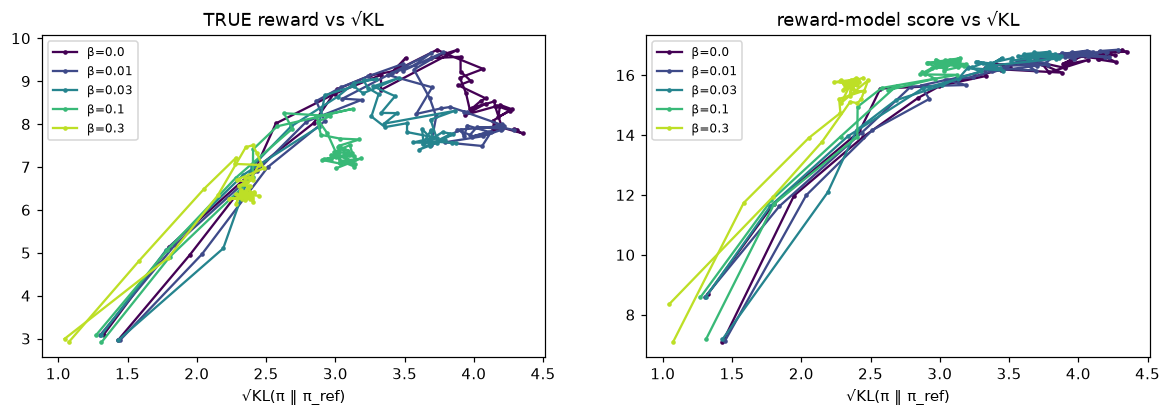

In [6]:
oo = load("overopt__")
betas = sorted({r["beta"] for r in oo})
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
colours = plt.cm.viridis(np.linspace(0, 0.9, len(betas)))
print(f"{'beta':>6} {'peak true reward':>17} {'at step':>8} {'final true':>11} {'final proxy':>12} {'final KL':>9}")
for beta, colour in zip(betas, colours):
    runs = [r for r in oo if r["beta"] == beta]
    for r in runs:
        kl = np.sqrt(np.maximum([e["kl"] for e in r["log"]], 0))
        axs[0].plot(kl, [e["true_reward"] for e in r["log"]], "o-", ms=2, color=colour, label=f"β={beta}" if r is runs[0] else None)
        axs[1].plot(kl, [e["proxy"] for e in r["log"]], "o-", ms=2, color=colour, label=f"β={beta}" if r is runs[0] else None)
    true = np.array([[e["true_reward"] for e in r["log"]] for r in runs]).mean(0)
    peak = int(true.argmax())
    print(f"{beta:>6} {true[peak]:>17.2f} {runs[0]['log'][peak]['step']:>8} {true[-1]:>11.2f} "
          f"{np.mean([r['log'][-1]['proxy'] for r in runs]):>12.2f} {np.mean([r['log'][-1]['kl'] for r in runs]):>9.1f}")
axs[0].set_title("TRUE reward vs √KL"); axs[1].set_title("reward-model score vs √KL")
for ax in axs: ax.set_xlabel("√KL(π ‖ π_ref)"); ax.legend(fontsize=8)
plt.show()

At every β the same thing happens. The reward-model score rises and levels off (about 16.7). The true reward peaks — 9.55 at step 200 with β = 0 — and then falls by 1 to 1.6 while the score holds steady.
The policy has moved into responses the reward model was never trained on, and it is wrong about them.

The KL penalty did **not** prevent the decline here. A larger β lowers the peak (9.55 at β = 0, 7.34 at β = 0.3) and the final value (7.98 against 6.36); it slows the policy down rather than steering it.
Within 600 steps, the best true reward came from stopping at the peak, which needs the true reward, which real RLHF does not have.
Gao et al. report the same (Section 3, Figure 9): the KL penalty "does not affect the KL_RL-gold reward frontier, and so the effect of the penalty on the gold score is akin to early stopping". Here too, every β traces the same rising curve of true reward against √KL.

## 5. Labelers who want something else

Same pipeline, three labelers, 3,000 pairs each, then RLHF (RLOO, β 0.05, 300 steps):

- **human**: labels by the true reward.
- **length-biased** (Singhal et al. 2023 found real preference data favours longer answers): true reward + 0.5 per token.
- **constitution**: a rule-following AI labeler (Bai et al. 2022 use a model guided by written principles; here the principle is a rule). The rule: "the response must mention the requested token, and repetition is bad". Reasonable-sounding, and it penalises exactly the repetition the true reward wants.

      labeler  agrees with true  RM acc vs true  true after RLHF  RM score  length
        human             1.000           0.893             8.20     22.97    10.2
  length_bias             0.793           0.813             6.62     25.69    10.4
 constitution             0.409           0.449             0.48     15.39     2.8


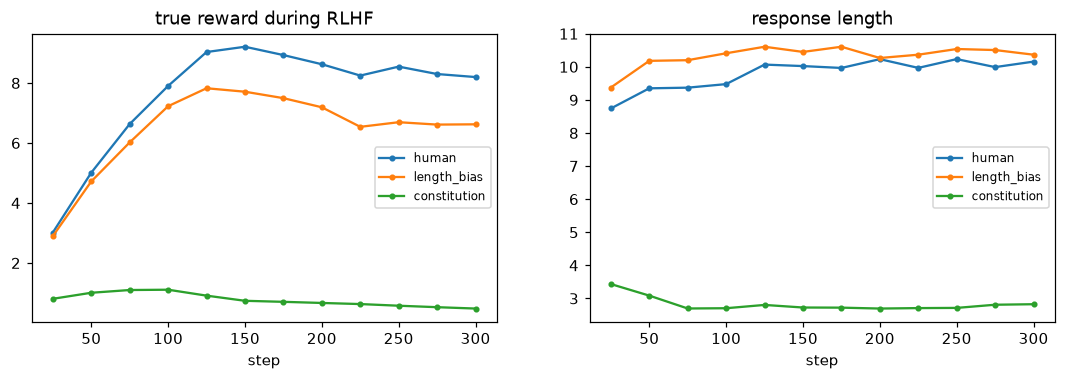

In [7]:
lab = {r["labeler"]: r for r in load("labelers__")}
print(f"{'labeler':>13} {'agrees with true':>17} {'RM acc vs true':>15} {'true after RLHF':>16} {'RM score':>9} {'length':>7}")
for name in ("human", "length_bias", "constitution"):
    r = lab[name]; last = r["log"][-1]
    print(f"{name:>13} {r['agreement_with_true']:>17.3f} {r['rm_accuracy_vs_true']:>15.3f} {last['true_reward']:>16.2f} "
          f"{last['proxy']:>9.2f} {last['length']:>7.1f}")
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
for name in ("human", "length_bias", "constitution"):
    log = lab[name]["log"]
    axs[0].plot([e["step"] for e in log], [e["true_reward"] for e in log], "o-", ms=3, label=name)
    axs[1].plot([e["step"] for e in log], [e["length"] for e in log], "o-", ms=3, label=name)
axs[0].set_title("true reward during RLHF"); axs[1].set_title("response length")
for ax in axs: ax.set_xlabel("step"); ax.legend(fontsize=8)
plt.show()

- **Length-biased labeler:** it agrees with the true reward on 79.3% of pairs, and its reward model leads RLHF to a true reward of 6.62 instead of 8.20.
  The length itself barely differs (10.4 against 10.2 tokens), because on this task the true optimum is also the longest response. The bias costs reward per token, not visible length. On real text, where good answers are not maximally long, Singhal et al. found length rising.
- **Constitution labeler:** it agrees with the true reward on **40.9%** of pairs — worse than a coin — because its rule penalises the repetition the task needs.
  RLHF on it reaches a reward-model score of 15.4 and a true reward of **0.48, below the 1.18 it started from**, with short responses (2.8 tokens): mention the token once, never repeat.
  The policy did exactly what the labeler rewarded. That is the general risk with AI or rubric feedback: the rule is a proxy, and optimisation finds where it parts from the goal.

## 6. DPO: the same pairs, no reward model

$\mathcal{L} = -\log\sigma\big(\beta[\log\frac{\pi(y_w)}{\pi_{ref}(y_w)} - \log\frac{\pi(y_l)}{\pi_{ref}(y_l)}]\big)$ ([`dpo.py`](../algos/dpo.py)): supervised training on the 3,000 human pairs, 4 epochs, 2 seeds per β.

β=0.03: final true reward [7.03, 6.81], length [8.0, 7.8]
β=0.1: final true reward [7.18, 6.99], length [8.3, 8.1]
β=0.3: final true reward [7.52, 7.09], length [9.0, 8.4]


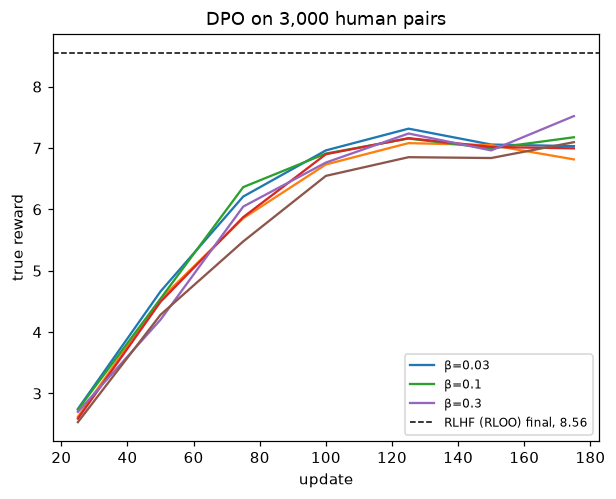

In [8]:
dpo_rows = load("dpo__")
for beta in sorted({r["beta"] for r in dpo_rows}):
    runs = [r for r in dpo_rows if r["beta"] == beta]
    print(f"β={beta}: final true reward {[round(r['log'][-1]['true_reward'], 2) for r in runs]}, length {[round(r['log'][-1]['length'], 1) for r in runs]}")
    for r in runs:
        plt.plot([e["update"] for e in r["log"]], [e["true_reward"] for e in r["log"]], label=f"β={beta}" if r is runs[0] else None)
rlhf_final = np.mean([r["log"][-1]["true_reward"] for r in est if r["estimator"] == "rloo"])
plt.axhline(rlhf_final, color="k", ls="--", lw=1, label=f"RLHF (RLOO) final, {rlhf_final:.2f}")
plt.xlabel("update"); plt.ylabel("true reward"); plt.legend(fontsize=8); plt.title("DPO on 3,000 human pairs"); plt.show()

DPO ends at a true reward of 6.8 to 7.5 across β, from 1.18, with no reward model and no sampling. RLHF with RLOO on a reward model from the same 3,000 pairs ends at 8.6.
HYPOTHESIS (unverified): DPO only moves probability between responses that appear in the pairs, all drawn from the reference policy, while RLHF samples and scores new responses (including the long all-target ones that the reference rarely writes).
DPO's curves dip only slightly at the end (at most 0.3 below their best), against falls of 1 to 1.6 for RLHF in section 4.

## 7. What one sample looks like

Live: the SFT policy, then the same policy after 150 steps of RLHF on the **true** reward (the best case, no reward model in between).

In [9]:
policy = sp.sft(n_steps=1_500, seed=0)
prompts = [3, 3, 5, 5]
fmt = lambda y: " ".join(str(t) for t in y if t != toy.EOS)
show = lambda pol, title: print(title + "\n" + "\n".join(
    f"  prompt {p}: {fmt(y):<28} r* = {toy.true_reward(p, y):5.1f}" for p, y in zip(prompts, pol.sample(prompts, torch.Generator().manual_seed(0)))))
show(policy, "SFT")
t0 = time.time()
rlhf.train(policy, rlhf.true_reward_fn, n_steps=150, estimator="rloo", eval_every=150)
show(policy, f"after RLHF on the true reward ({time.time() - t0:.0f} s)")

SFT
  prompt 3: 6 5 2 7 3 3                  r* =   0.8
  prompt 3: 3 2 3 7 3 4 3                r* =   3.1
  prompt 5: 4 4 3 5 6 3 6                r* =  -0.8
  prompt 5: 5 5 5 5 5                    r* =   5.0


after RLHF on the true reward (4 s)
  prompt 3: 3 3 3 3 3 3 3 3 3 3 3 3      r* =  12.0
  prompt 3: 3 3 3 3 3 3 3 3 3 3 3 3      r* =  12.0
  prompt 5: 5 5 5 5 5 5 5 5 5 5 5 5      r* =  12.0
  prompt 5: 5 5 5 5 5 5 5 5 5 5 5 5      r* =  12.0


## 8. What breaks, and how you would know

| symptom | likely cause |
| --- | --- |
| reward-model score rises, human ratings fall | over-optimisation; raise β or stop at the peak (section 4). In a real run you need held-out human evaluation to see it at all |
| responses get longer every update | the reward model prefers length; check length against reward |
| policy optimises the labeler's rule, not the goal | AI or rubric labels encode a proxy; measure agreement with the goal on a sample |
| KL negative in the log | the plain log-ratio estimator on one batch; use the k3 estimator |
| GRPO advantages all zero | one sample per prompt; group std is undefined |
| DPO lowers the chosen responses' likelihood | expected: only the margin must grow; judge by the outcome |
| DPO reference = policy | every log-ratio is 0; freeze a copy at the start |